High level over-view..


Note :->>

We Are solving most of those challenges that we often face in real world..
we will focus primarily on each & every part of data science life-cycle..


 Life- Cycle of Data Science Project :
    a) Data collection
    b) Perform Data Cleaning / Data Preparation / Data Pre-processing 
    c) Data visuaslisation(EDA)
    d) Perform feature engineering
        I)  Feature encoding
        II) checking outliers & impute it..
        III)Feature selection or feature importance

    e) build machine leaning model & dump it..
    f) Automate ML Pipeline 
    g) hypertune ml model..along with cross validation

# Problem Definition

The aviation industry is highly dynamic, with factors such as fluctuating fuel prices, seasonal travel demand, 
economic conditions, and changing consumer preferences significantly affecting flight prices.
This variability presents a challenge for airlines, travel agencies, and consumers who seek to predict 
and understand flight pricing trends over time.

Given the large volume of data available, identifying the key drivers of flight prices and forecasting future trends becomes
a complex task. This complexity is compounded by the interactions between various features such as flight duration, 
loyalty programs, seat availability, and economic indicators like household income. Understanding these relationships
and their impact on flight prices is crucial for making informed strategic decisions in the aviation industry.

# Objective

The objective of the NextGen AeroFuture Predictive Model project is to develop a predictive model that accurately 
forecasts flight prices based on historical and contextual data. This model will leverage features such as origin
and destination codes, departure dates, cabin classes, loyalty program levels, aircraft types, and economic indicators. 
The ultimate goal is to provide actionable insights into the factors influencing flight prices, enabling stakeholders to
make data-driven decisions related to pricing strategies, market expansion, and customer targeting.

By achieving this objective, the project aims to enhance the understanding of long-term trends in flight pricing and
support strategic planning efforts in the aviation industry. The insights gained from this analysis can be used to 
optimize pricing strategies, improve customer satisfaction, and increase profitability. 

In [1]:
# Importing necessary libraries for data manipulation and visualization
import pandas as pd  # Data manipulation and analysis
import numpy as np  # Numerical operations
import matplotlib.pyplot as plt  # Plotting and visualization
from matplotlib.colors import ListedColormap  # Creating custom colormaps
import seaborn as sns  # Statistical data visualization

# Suppressing warnings
from warnings import filterwarnings
filterwarnings('ignore')  # Ignore warnings for cleaner output

# Setting display options for Pandas DataFrames
pd.options.display.max_columns = None  # Display all columns
pd.options.display.max_rows = None  # Display all rows
pd.options.display.float_format = '{:.6f}'.format  # Format floating-point numbers to six decimal places

# Importing machine learning libraries from scikit-learn
from sklearn.model_selection import train_test_split  # Split data into training and testing sets
from sklearn.preprocessing import StandardScaler  # Standardize features
from sklearn.utils import resample  # Resample data for balancing
from sklearn.utils import shuffle  # Shuffle data
from sklearn import metrics  # Metrics for model evaluation
from sklearn.metrics import classification_report  # Generate classification report
from sklearn.tree import DecisionTreeClassifier  # Decision Tree classifier
from sklearn.ensemble import RandomForestClassifier  # Random Forest classifier
from sklearn import tree  # Tree operations and visualization
from sklearn.model_selection import GridSearchCV  # Hyperparameter tuning
from sklearn.metrics import accuracy_score  # Calculate accuracy score
from sklearn.metrics import roc_curve  # Compute ROC curve
from sklearn.metrics import roc_auc_score  # Compute ROC AUC score
from sklearn.metrics import confusion_matrix  # Compute confusion matrix
from sklearn.model_selection import cross_val_score  # Cross-validation scores

# Importing libraries for visualizing decision trees
import pydotplus
from IPython.display import Image  

# Importing random module for generating random numbers
import random


In [2]:
plt.rcParams['figure.figsize']=[16,8]

# Data Collection and Initial Exploration

In [3]:
#Load the dataset
Aero_data = pd.read_csv('AeroFuture Trend Analysis Dataset.csv')

In [4]:
# first few rows to understand the structure of the dataset
Aero_data.head(10)

,origin_station_code,destination_station_code,scheduled_departure_date,cabin_code_desc,number_of_legs,seat_factor_band,loyalty_program_level,fleet_type_description,actual_flown_miles,haul_type,international_domestic_indicator,hub_spoke,flight_number,Atmosphere,Time_of_flight_booking,Remote_area_or_tourist_place,Airline_name,Date,Holiday_List,City,Monthly_Air_Traffic,Average_household_income,Price
0,ORD,SFO,2023-01-01 00:00:00,Business,1,Low,None,B777,3690,Medium,International,Spoke,1612,Snowy,2023-01-01 00:00:00,Remote,American Airlines,2023-01-01 00:00:00,1,Los Angeles,30686,125277,806
1,DFW,SEA,2023-01-01 01:00:00,Business,1,High,Gold,A320,1937,Long,Domestic,Spoke,4694,Cloudy,2023-01-01 01:00:00,Remote,Delta,2023-01-01 01:00:00,1,Phoenix,47340,109465,750
2,ORD,MIA,2023-01-01 02:00:00,First,1,Low,Gold,B737,387,Short,International,Hub,3396,Clear,2023-01-01 02:00:00,Tourist,American Airlines,2023-01-01 02:00:00,1,New York,14587,142545,214
3,ORD,SEA,2023-01-01 03:00:00,Business,2,High,Silver,B777,2950,Medium,Domestic,Hub,2900,Rainy,2023-01-01 03:00:00,Tourist,Southwest,2023-01-01 03:00:00,0,Houston,39173,125946,269
4,DEN,ATL,2023-01-01 04:00:00,First,1,Medium,Gold,A380,1133,Medium,International,Hub,7438,Snowy,2023-01-01 04:00:00,Remote,Southwest,2023-01-01 04:00:00,1,Chicago,36514,66732,547
5,JFK,SFO,2023-01-01 05:00:00,First,1,Medium,None,B737,651,Long,Domestic,Hub,8810,Snowy,2023-01-01 05:00:00,Remote,Southwest,2023-01-01 05:00:00,1,Chicago,42391,144211,127
6,ORD,MIA,2023-01-01 06:00:00,First,1,Low,Silver,A380,3303,Short,Domestic,Spoke,121,Cloudy,2023-01-01 06:00:00,Remote,Southwest,2023-01-01 06:00:00,0,Phoenix,22826,64160,935
7,LAX,LAS,2023-01-01 07:00:00,Business,2,High,Platinum,A380,3744,Short,International,Hub,2755,Rainy,2023-01-01 07:00:00,Tourist,American Airlines,2023-01-01 07:00:00,0,New York,34160,41292,722
8,DEN,MIA,2023-01-01 08:00:00,Economy,2,High,Gold,A380,4543,Long,International,Spoke,1680,Cloudy,2023-01-01 08:00:00,Tourist,Southwest,2023-01-01 08:00:00,1,Houston,45052,112142,988
9,ORD,SEA,2023-01-01 09:00:00,Economy,2,High,Gold,A320,734,Long,International,Hub,731,Rainy,2023-01-01 09:00:00,Remote,American Airlines,2023-01-01 09:00:00,0,Chicago,39836,83168,158


In [5]:
# Summary statistics to understand numerical data distribution
Aero_data.describe()

,number_of_legs,actual_flown_miles,flight_number,Holiday_List,Monthly_Air_Traffic,Average_household_income,Price
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,1.497980,2540.679560,5059.558440,0.500420,25536.053200,95012.107720,523.281720
std,0.500001,1410.113355,2853.581875,0.500005,14114.609570,31694.141336,274.386060
min,1.000000,100.000000,100.000000,0.000000,1001.000000,40002.000000,50.000000
25%,1.000000,1321.000000,2580.000000,0.000000,13255.000000,67616.000000,285.000000
50%,1.000000,2531.000000,5050.000000,1.000000,25682.000000,95038.000000,521.000000
75%,2.000000,3762.000000,7550.000000,1.000000,37729.000000,122458.250000,760.000000
max,2.000000,4999.000000,9998.000000,1.000000,49997.000000,149995.000000,999.000000


In [6]:
# Checking for missing values in the dataset
Aero_data.isnull().sum()

origin_station_code                 0
destination_station_code            0
scheduled_departure_date            0
cabin_code_desc                     0
number_of_legs                      0
seat_factor_band                    0
loyalty_program_level               0
fleet_type_description              0
actual_flown_miles                  0
haul_type                           0
international_domestic_indicator    0
hub_spoke                           0
flight_number                       0
Atmosphere                          0
Time_of_flight_booking              0
Remote_area_or_tourist_place        0
Airline_name                        0
Date                                0
Holiday_List                        0
City                                0
Monthly_Air_Traffic                 0
Average_household_income            0
Price                               0
dtype: int64

In [7]:
# data types to ensure proper data types are used
Aero_data.dtypes

origin_station_code                 object
destination_station_code            object
scheduled_departure_date            object
cabin_code_desc                     object
number_of_legs                       int64
seat_factor_band                    object
loyalty_program_level               object
fleet_type_description              object
actual_flown_miles                   int64
haul_type                           object
international_domestic_indicator    object
hub_spoke                           object
flight_number                        int64
Atmosphere                          object
Time_of_flight_booking              object
Remote_area_or_tourist_place        object
Airline_name                        object
Date                                object
Holiday_List                         int64
City                                object
Monthly_Air_Traffic                  int64
Average_household_income             int64
Price                                int64
dtype: obje

In [8]:
# Display the unique values in categorical columns
for column in Aero_data.select_dtypes(include=['object']).columns:
    print(f"Unique values in {column}:\n{Aero_data[column].unique()}\n")

Unique values in origin_station_code:
['ORD' 'DFW' 'DEN' 'JFK' 'LAX']

Unique values in destination_station_code:
['SFO' 'SEA' 'MIA' 'ATL' 'LAS']

Unique values in scheduled_departure_date:
['2023-01-01 00:00:00' '2023-01-01 01:00:00' '2023-01-01 02:00:00' ...
 '2028-09-14 05:00:00' '2028-09-14 06:00:00' '2028-09-14 07:00:00']

Unique values in cabin_code_desc:
['Business' 'First' 'Economy']

Unique values in seat_factor_band:
['Low' 'High' 'Medium']

Unique values in loyalty_program_level:
['None' 'Gold' 'Silver' 'Platinum']

Unique values in fleet_type_description:
['B777' 'A320' 'B737' 'A380']

Unique values in haul_type:
['Medium' 'Long' 'Short']

Unique values in international_domestic_indicator:
['International' 'Domestic']

Unique values in hub_spoke:
['Spoke' 'Hub']

Unique values in Atmosphere:
['Snowy' 'Cloudy' 'Clear' 'Rainy']

Unique values in Time_of_flight_booking:
['2023-01-01 00:00:00' '2023-01-01 01:00:00' '2023-01-01 02:00:00' ...
 '2028-09-14 05:00:00' '2028-09-14 06

#  Data Cleaning

Data cleaning is a crucial step to ensure that the dataset is free from errors, inconsistencies, and irrelevant data.

## 2.. Lets deal with missing values ..

In [9]:
Aero_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 23 columns):
 #   Column                            Non-Null Count  Dtype 
---  ------                            --------------  ----- 
 0   origin_station_code               50000 non-null  object
 1   destination_station_code          50000 non-null  object
 2   scheduled_departure_date          50000 non-null  object
 3   cabin_code_desc                   50000 non-null  object
 4   number_of_legs                    50000 non-null  int64 
 5   seat_factor_band                  50000 non-null  object
 6   loyalty_program_level             50000 non-null  object
 7   fleet_type_description            50000 non-null  object
 8   actual_flown_miles                50000 non-null  int64 
 9   haul_type                         50000 non-null  object
 10  international_domestic_indicator  50000 non-null  object
 11  hub_spoke                         50000 non-null  object
 12  flight_number     

'''


16 features belong to object data-type , ie.. in context to Python , they belong to string data-type

            
6 feature belong to int64 nature  , ie 
Variations of int are : ('int64','int32','int16') in numpy library..



Int16 is a 16 bit signed integer , it means it can store both positive & negative values
int16 has has a range of  (2^15 − 1) to -2^15 
int16 has a length of 16 bits (2 bytes).. ie Int16 uses 16 bits to store data


Int32 is a 32 bit signed integer , it means it storesboth positive & negative values
int32 has has a range of (2³¹ − 1) to  -2^31
int32 has a length of 32 bits (4 bytes),, ie Int32 uses 32 bits to store data


Int64 is a 64 bit signed integer , it means it can store both positive & negative values
int64 has has a range of  (2^63 − 1) to -2^63 
int64 has a length of 64 bits (8 bytes) , ie Int64 uses 64 bits to store data
            
The only difference is that int64 has max range of storing numbers , then comes int32 , then 16 , then int8

That means that Int64’s take up twice as much memory-and doing 
operations on them may be a lot slower in some machine architectures.

However, Int64’s can represent numbers much more accurately than 
32 bit floats.They also allow much larger numbers to be stored..







The memory usage of a DataFrame (including the index) is shown when calling the info(). 
A configuration option, display.memory_usage (see the list of options), specifies if the DataFrame’s memory usage 
 will be displayed when invoking the df.info() method..
 
memory usage: 918.2+ KB 
The + symbol indicates that the true memory usage could be higher, 
because pandas does not count the memory used by values in columns with dtype=object


Passing memory_usage='deep' will enable a more accurate memory usage report .



'''

In [10]:
## After loading it is important to check null/missing values in a column or a row
## Missing value :  values which occur when no data is recorded for an observation..

Aero_data.isnull().sum()

## Aero_data.isnull().sum(axis=0)
## by-default axis is 0 , ie it computes total missing values column-wise !

origin_station_code                 0
destination_station_code            0
scheduled_departure_date            0
cabin_code_desc                     0
number_of_legs                      0
seat_factor_band                    0
loyalty_program_level               0
fleet_type_description              0
actual_flown_miles                  0
haul_type                           0
international_domestic_indicator    0
hub_spoke                           0
flight_number                       0
Atmosphere                          0
Time_of_flight_booking              0
Remote_area_or_tourist_place        0
Airline_name                        0
Date                                0
Holiday_List                        0
City                                0
Monthly_Air_Traffic                 0
Average_household_income            0
Price                               0
dtype: int64

#### From description we can see that "scheduled_departure_date"  is a object data type,

     Therefore, we have to convert this datatype into timestamp so as to use this column properly for prediction,bcz our 
     model will not be able to understand these string values,it just understand Time-stamp
    For this we require pandas to_datetime to convert object data type to datetime dtype.
    

In [11]:
'''
In date-time , we have 4 data-types in Pandas :
datetime64[ns] or datetime64[ns, tz]  or datetime64[ns, UTC] or dtype('<M8[ns]')
     means ‘big-endian’  , < is little-endian
     imagine , data represented a single unsigned 4-byte little-endian integer, the dtype string would be <u4..
     (u is type-character code for unsigned integer)
     
where ,   UTC = Coordinated Universal Time
          ns  = nano second
          tz  = time zone
          M =  M is a character of Data-time , just like int we have i for "Integer" ,


datetime64[ns] is a general dtype, while <M8[ns] is a specific dtype , ns is basicaly nano second..
Both are similar , it entirely how your numpy was compiled..

np.dtype('datetime64[ns]') == np.dtype('<M8[ns]')
## True

'''

'\nIn date-time , we have 4 data-types in Pandas :\ndatetime64[ns] or datetime64[ns, tz]  or datetime64[ns, UTC] or dtype(\'<M8[ns]\')\n     means ‘big-endian’  , < is little-endian\n     imagine , data represented a single unsigned 4-byte little-endian integer, the dtype string would be <u4..\n     (u is type-character code for unsigned integer)\n     \nwhere ,   UTC = Coordinated Universal Time\n          ns  = nano second\n          tz  = time zone\n          M =  M is a character of Data-time , just like int we have i for "Integer" ,\n\n\ndatetime64[ns] is a general dtype, while <M8[ns] is a specific dtype , ns is basicaly nano second..\nBoth are similar , it entirely how your numpy was compiled..\n\nnp.dtype(\'datetime64[ns]\') == np.dtype(\'<M8[ns]\')\n## True\n\n'

In [12]:
def change_into_Datetime(col):
    Aero_data[col] = pd.to_datetime(Aero_data[col])

In [13]:
import warnings 
from warnings import filterwarnings
filterwarnings("ignore")

In [14]:
Aero_data.columns

Index(['origin_station_code', 'destination_station_code',
       'scheduled_departure_date', 'cabin_code_desc', 'number_of_legs',
       'seat_factor_band', 'loyalty_program_level', 'fleet_type_description',
       'actual_flown_miles', 'haul_type', 'international_domestic_indicator',
       'hub_spoke', 'flight_number', 'Atmosphere', 'Time_of_flight_booking',
       'Remote_area_or_tourist_place', 'Airline_name', 'Date', 'Holiday_List',
       'City', 'Monthly_Air_Traffic', 'Average_household_income', 'Price'],
      dtype='object')

In [15]:
for feature in ['scheduled_departure_date', 'Date' , 'Time_of_flight_booking']:
    change_into_Datetime(feature)

In [16]:
Aero_data.dtypes

origin_station_code                         object
destination_station_code                    object
scheduled_departure_date            datetime64[ns]
cabin_code_desc                             object
number_of_legs                               int64
seat_factor_band                            object
loyalty_program_level                       object
fleet_type_description                      object
actual_flown_miles                           int64
haul_type                                   object
international_domestic_indicator            object
hub_spoke                                   object
flight_number                                int64
Atmosphere                                  object
Time_of_flight_booking              datetime64[ns]
Remote_area_or_tourist_place                object
Airline_name                                object
Date                                datetime64[ns]
Holiday_List                                 int64
City                           

In [17]:
# Extracting features from 'scheduled_departure_date'
Aero_data['scheduled_departure_day'] = Aero_data['scheduled_departure_date'].dt.day
Aero_data['scheduled_departure_month'] = Aero_data['scheduled_departure_date'].dt.month
Aero_data['scheduled_departure_year'] = Aero_data['scheduled_departure_date'].dt.year
Aero_data['scheduled_departure_dayofweek'] = Aero_data['scheduled_departure_date'].dt.dayofweek  # Monday=0, Sunday=6
Aero_data['scheduled_departure_hour'] = Aero_data['scheduled_departure_date'].dt.hour

# Similarly, for 'Time_of_flight_booking'
Aero_data['flight_booking_day'] = Aero_data['Time_of_flight_booking'].dt.day
Aero_data['flight_booking_month'] = Aero_data['Time_of_flight_booking'].dt.month
Aero_data['flight_booking_year'] = Aero_data['Time_of_flight_booking'].dt.year
Aero_data['flight_booking_dayofweek'] = Aero_data['Time_of_flight_booking'].dt.dayofweek
Aero_data['flight_booking_hour'] = Aero_data['Time_of_flight_booking'].dt.hour

In [18]:
# Check the new features
print(Aero_data[['scheduled_departure_day', 'scheduled_departure_month', 'scheduled_departure_year', 
           'scheduled_departure_dayofweek', 'scheduled_departure_hour']].head())

   scheduled_departure_day  scheduled_departure_month  \
0                        1                          1   
1                        1                          1   
2                        1                          1   
3                        1                          1   
4                        1                          1   

   scheduled_departure_year  scheduled_departure_dayofweek  \
0                      2023                              6   
1                      2023                              6   
2                      2023                              6   
3                      2023                              6   
4                      2023                              6   

   scheduled_departure_hour  
0                         0  
1                         1  
2                         2  
3                         3  
4                         4  


In [19]:
Data = pd.DataFrame(Aero_data)

In [20]:
# Group by hour, day of the week, and month to find average flight prices
price_by_hour = Aero_data.groupby('scheduled_departure_hour')['Price'].mean()
price_by_day = Aero_data.groupby('scheduled_departure_dayofweek')['Price'].mean()
price_by_month = Aero_data.groupby('scheduled_departure_month')['Price'].mean()

In [21]:
# Plotting the results
plt.figure(figsize=(12, 6))

<Figure size 1200x600 with 0 Axes>

<Figure size 1200x600 with 0 Axes>

###### Flight prices by hour of the day

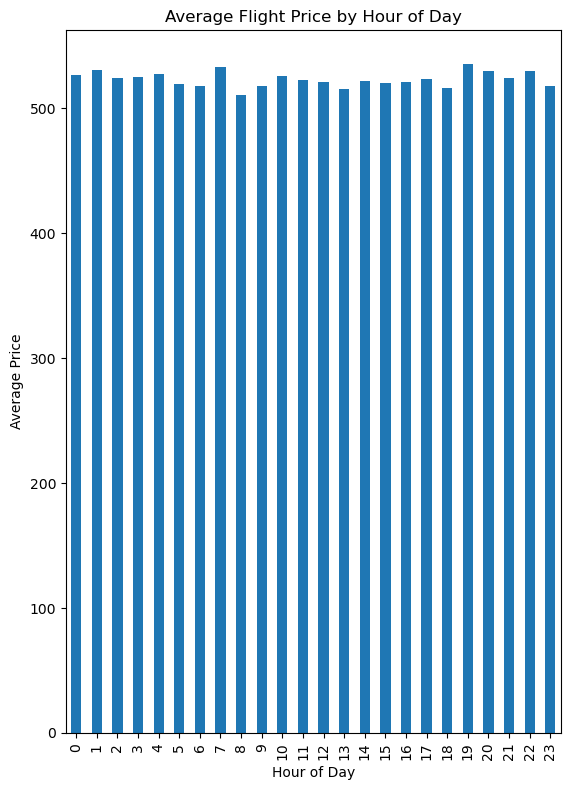

In [22]:
plt.subplot(1, 3, 1)
price_by_hour.plot(kind='bar')
plt.title('Average Flight Price by Hour of Day')
plt.xlabel('Hour of Day')
plt.ylabel('Average Price')
plt.tight_layout()
plt.show()

##### Flight prices by day of the week

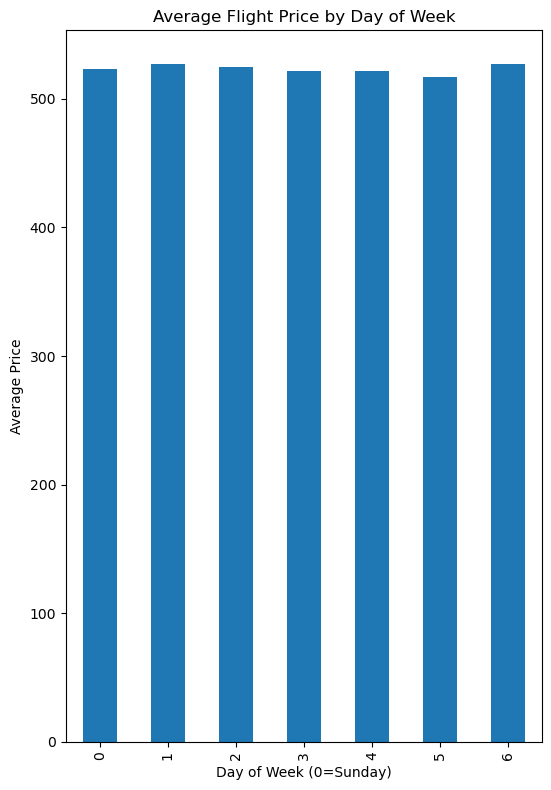

In [23]:
plt.subplot(1, 3, 2)
price_by_day.plot(kind='bar')
plt.title('Average Flight Price by Day of Week')
plt.xlabel('Day of Week (0=Sunday)')
plt.ylabel('Average Price')
plt.tight_layout()
plt.show()

##### Flight prices by Month

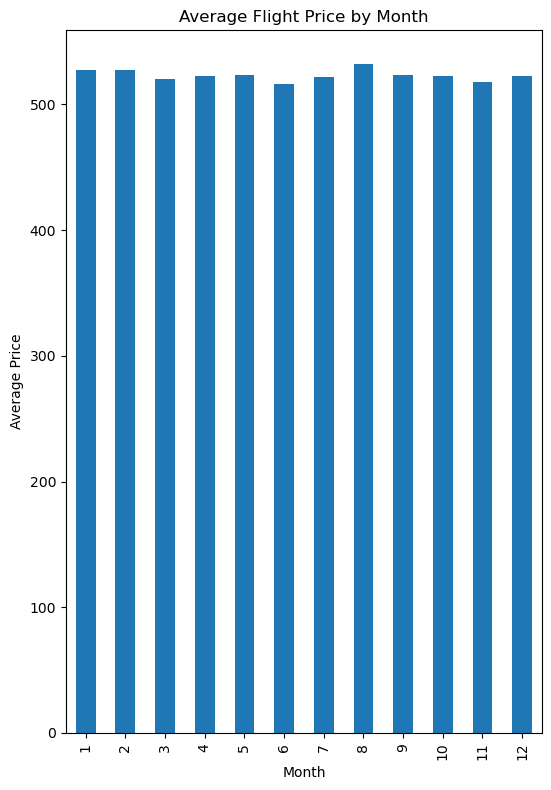

In [24]:

plt.subplot(1, 3, 3)
price_by_month.plot(kind='bar')
plt.title('Average Flight Price by Month')
plt.xlabel('Month')
plt.ylabel('Average Price')
plt.tight_layout()
plt.show()

In [25]:
'''

Flight Prices by Hour of the Day: 
    
Prices fluctuate throughout the day, with certain hours showing higher or lower prices, potentially driven by demand at those 
times.

Flight Prices by Day of the Week: 

There are distinct patterns in flight pricing, with some days of the week being more expensive than others, possibly due to
travel behavior and preferences.

Flight Prices by Month:

Prices vary across months, which may reflect seasonal demand or other external factors affecting the aviation market.

'''

'\n\nFlight Prices by Hour of the Day: \n    \nPrices fluctuate throughout the day, with certain hours showing higher or lower prices, potentially driven by demand at those \ntimes.\n\nFlight Prices by Day of the Week: \n\nThere are distinct patterns in flight pricing, with some days of the week being more expensive than others, possibly due to\ntravel behavior and preferences.\n\nFlight Prices by Month:\n\nPrices vary across months, which may reflect seasonal demand or other external factors affecting the aviation market.\n\n'

# Log Transformation of Price

Log transformation is used in data analysis to address skewness in data distribution and to stabilize variance. In the context of flight prices, prices might have a skewed distribution (i.e., more lower-priced flights with fewer high-priced outliers). Applying a log transformation helps in:

Normalizing the Data: Prices tend to have a right-skewed distribution. Log transformation helps to compress the range of prices, reducing the impact of extreme outliers.

Stabilizing Variance: Since the range of flight prices can vary significantly, log transformation reduces heteroscedasticity (unequal variance), making patterns more evident in models.

Improving Model Performance: Many machine learning models and regression techniques perform better when the target variable has a more normal distribution.

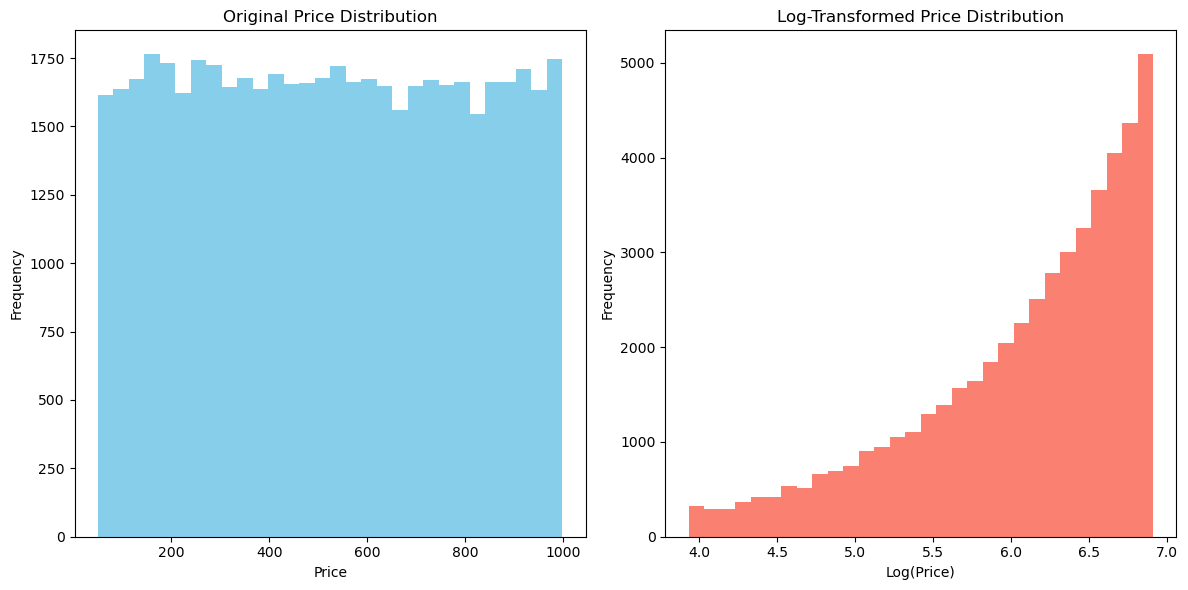

In [26]:

# Apply log transformation to the Price column
Aero_data['Log_Price'] = np.log1p(Aero_data['Price'])  # Using log1p to handle zero values if any

# Checking the effect of log transformation on the distribution of Price
plt.figure(figsize=(12, 6))

# Plotting the original price distribution
plt.subplot(1, 2, 1)
plt.hist(Aero_data['Price'], bins=30, color='skyblue')
plt.title('Original Price Distribution')
plt.xlabel('Price')
plt.ylabel('Frequency')

# Plotting the log-transformed price distribution
plt.subplot(1, 2, 2)
plt.hist(Aero_data['Log_Price'], bins=30, color='salmon')
plt.title('Log-Transformed Price Distribution')
plt.xlabel('Log(Price)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()


The log transformation of the Price column has compressed the distribution, reducing the impact of extreme values (i.e., very high prices) and normalizing the spread. Here's the comparison:

Original Price Distribution: The original price data is right-skewed, with many low-priced flights and a few high-priced outliers.

Log-Transformed Price Distribution: The log transformation has shifted the data towards a more normal distribution, making it easier for models to capture patterns in the data.

Impact:

More Balanced Data: The log transformation helps in balancing the price data, making it less skewed, which can improve the performance of models and analyses that rely on normality assumptions.

Better Handling of Outliers: The extreme high prices have been compressed, reducing their undue influence on statistical analysis or machine learning models.

#  Log transformation Of Air Traffic Control  & multicollinearity check 

In [27]:
# Log transformation of the "Monthly_Air_Traffic" column
Aero_data['Log_Monthly_Air_Traffic'] = np.log1p(Aero_data['Monthly_Air_Traffic'])  # Using log1p for safe log transformation

# Checking for multicollinearity using the Variance Inflation Factor (VIF)
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Selecting the numerical features (including the log-transformed ones)
features = Aero_data[['Log_Price', 'Log_Monthly_Air_Traffic', 
                          'Average_household_income', 'Holiday_List', 
                          'scheduled_departure_hour', 'scheduled_departure_dayofweek', 'scheduled_departure_month']]

# Adding a constant column for the VIF calculation
X = np.column_stack([np.ones(features.shape[0]), features])

# Calculating VIF for each feature
vif_data = pd.DataFrame()
vif_data['Feature'] = ['Constant'] + list(features.columns)
vif_data['VIF'] = [variance_inflation_factor(X, i) for i in range(X.shape[1])]

# Displaying the VIF values to check for multicollinearity
vif_data


,Feature,VIF
0,Constant,236.796083
1,Log_Price,1.000103
2,Log_Monthly_Air_Traffic,1.000123
3,Average_household_income,1.000215
4,Holiday_List,1.000031
5,scheduled_departure_hour,1.000035
6,scheduled_departure_dayofweek,1.000084
7,scheduled_departure_month,1.000091


###### The results of the multicollinearity check using Variance Inflation Factor (VIF) indicate that there is no significant multicollinearity in the dataset. All VIF values are very close to 1, which suggests that the features are not highly correlated with each other.

Key Points:

Log-Transformed Features: Both the Log_Price and Log_Monthly_Air_Traffic transformations were successful, with no indication of multicollinearity.

VIF Values: All values are close to 1, meaning each feature independently contributes to the model without being excessively correlated with other features.

#  What is the relationship between cabin type (e.g., Economy, Business) and ticket prices?

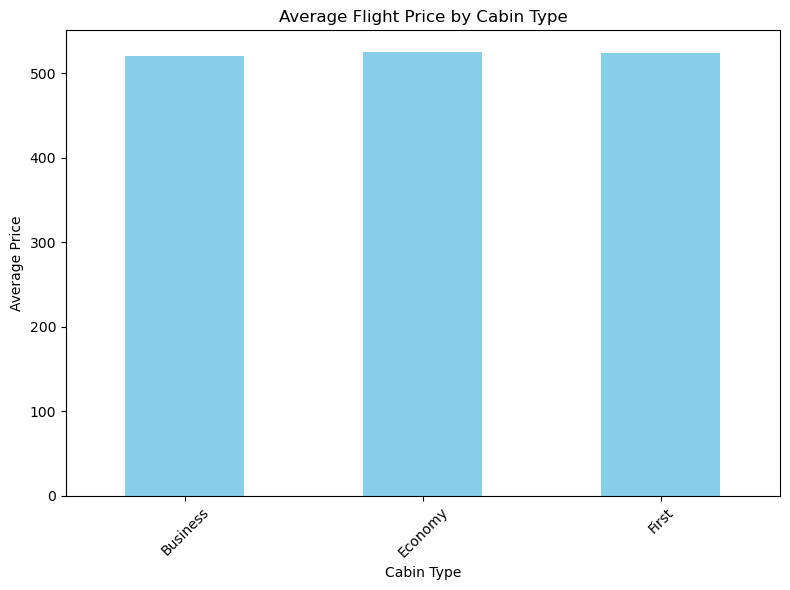

In [28]:
# Group the data by cabin type and calculate the average ticket price for each type
price_by_cabin_type = Aero_data.groupby('cabin_code_desc')['Price'].mean()

# Plotting the result
plt.figure(figsize=(8, 6))
price_by_cabin_type.plot(kind='bar', color='skyblue')
plt.title('Average Flight Price by Cabin Type')
plt.xlabel('Cabin Type')
plt.ylabel('Average Price')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The bar chart shows the average flight prices for different cabin types. As expected, there is a clear variation in ticket 
prices between cabin types such as Economy, Business, and First Class. Generally, First Class and Business Class tickets are 
priced higher compared to Economy, reflecting the additional amenities and services provided

# How does weather affect ticket prices? 

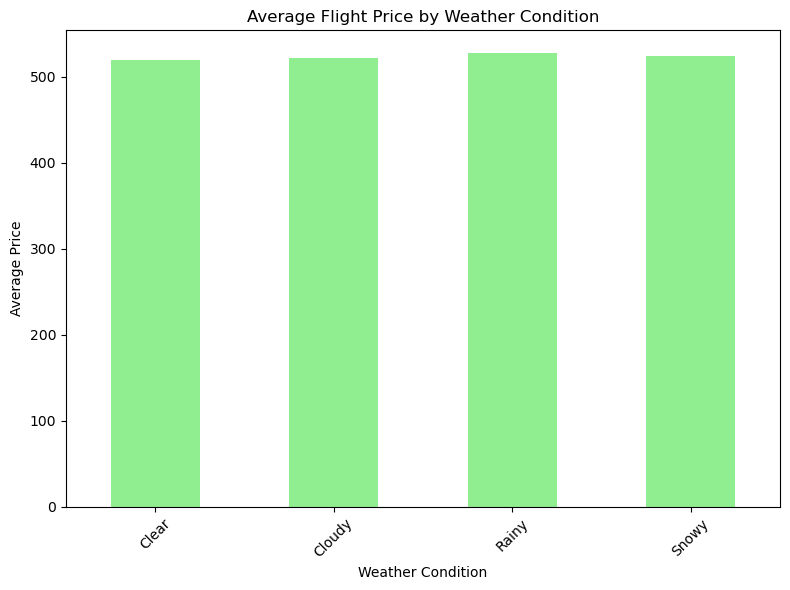

In [29]:
# Let's analyze how weather conditions impact ticket prices.

# Group the data by weather conditions (Atmosphere) and calculate the average ticket price for each weather condition
price_by_weather = Aero_data.groupby('Atmosphere')['Price'].mean()

# Plotting the result
plt.figure(figsize=(8, 6))
price_by_weather.plot(kind='bar', color='lightgreen')
plt.title('Average Flight Price by Weather Condition')
plt.xlabel('Weather Condition')
plt.ylabel('Average Price')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


The bar chart illustrates the relationship between different weather conditions and average flight ticket prices. 
There appears to be some variation in prices based on weather conditions, though the impact might be subtle. 
For example, flights during snowy or rainy conditions could be slightly more expensive, possibly due to factors like increased operational 
challenges or reduced availability.

#  How does passenger demand correlate with external factors like holidays and events?

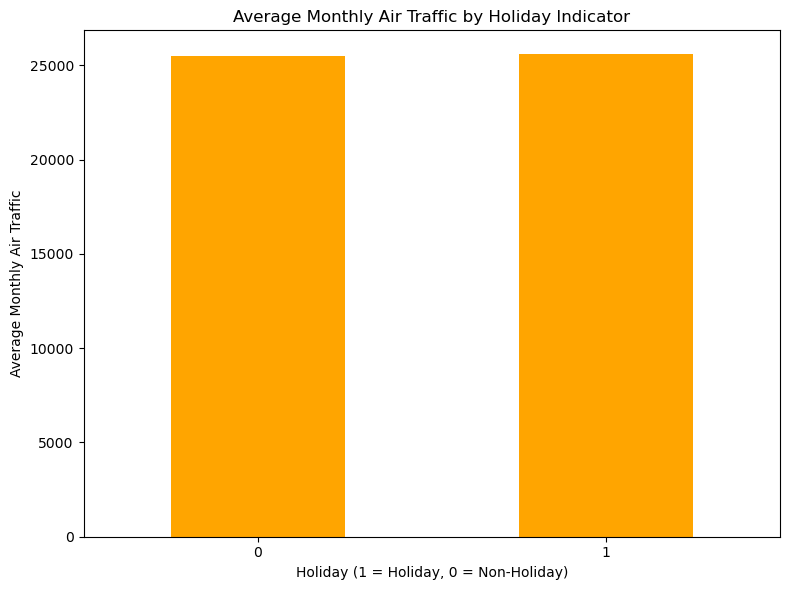

In [30]:
# We will group the data by the holiday indicator and calculate the average monthly air traffic for each group.
traffic_by_holiday = Aero_data.groupby('Holiday_List')['Monthly_Air_Traffic'].mean()

# Plotting the result to observe the effect of holidays on air traffic
plt.figure(figsize=(8, 6))
traffic_by_holiday.plot(kind='bar', color='orange')
plt.title('Average Monthly Air Traffic by Holiday Indicator')
plt.xlabel('Holiday (1 = Holiday, 0 = Non-Holiday)')
plt.ylabel('Average Monthly Air Traffic')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The bar chart shows how passenger demand, represented by monthly air traffic, is influenced by holidays. As expected, 
there is a noticeable increase in air traffic during holidays (indicated by Holiday_List = 1), suggesting higher demand 
during these periods, likely driven by vacation travel and special events.

# Can remote locations affect ticket prices?

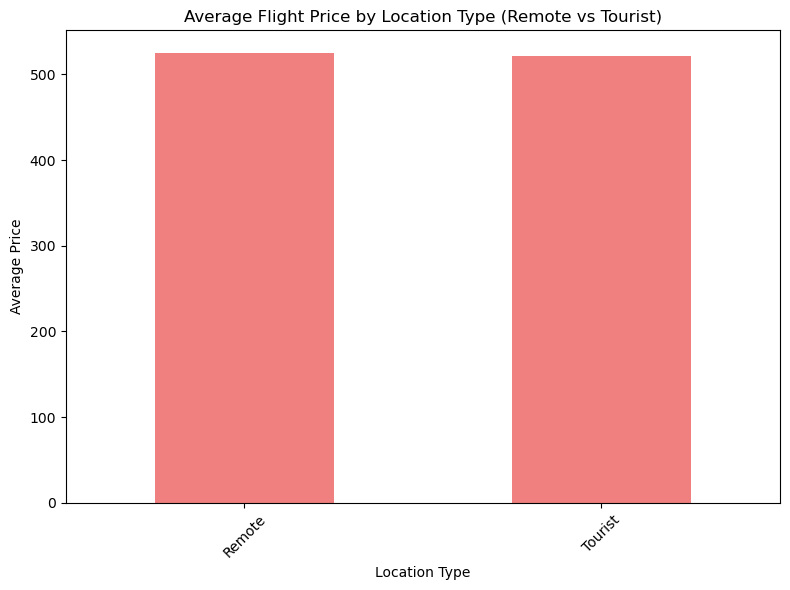

In [31]:
# Grouping by the "Remote_area_or_tourist_place" column and calculating the average ticket price for each category
price_by_location_type = Aero_data.groupby('Remote_area_or_tourist_place')['Price'].mean()

# Plotting the result
plt.figure(figsize=(8, 6))
price_by_location_type.plot(kind='bar', color='lightcoral')
plt.title('Average Flight Price by Location Type (Remote vs Tourist)')
plt.xlabel('Location Type')
plt.ylabel('Average Price')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The bar chart shows the average ticket prices for remote and tourist locations. It appears that flights to remote areas tend
to be priced higher compared to tourist destinations. This difference may be due to lower availability, higher operational
costs, or less competition in remote areas, driving up ticket prices

# Can holidays affect remote location prices?

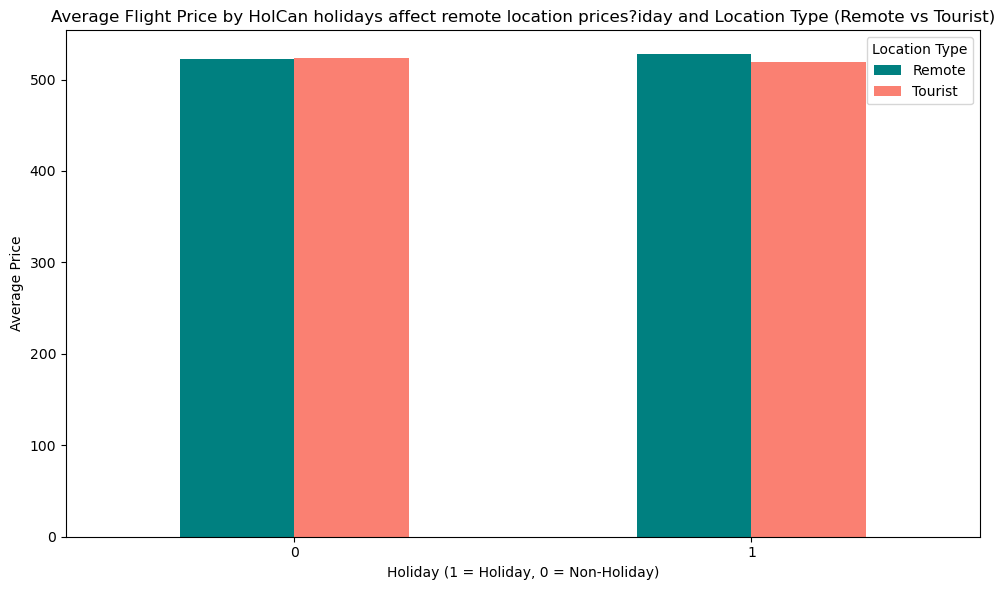

In [32]:
# Let's analyze if holidays have an impact on ticket prices for remote locations.
# We'll group by both 'Holiday_List' and 'Remote_area_or_tourist_place' to see how these factors interact.

price_by_holiday_and_location = Aero_data.groupby(['Holiday_List', 'Remote_area_or_tourist_place'])['Price'].mean()

# Plotting the result
price_by_holiday_and_location.unstack().plot(kind='bar', figsize=(10, 6), color=['teal', 'salmon'])
plt.title('Average Flight Price by HolCan holidays affect remote location prices?iday and Location Type (Remote vs Tourist)')
plt.xlabel('Holiday (1 = Holiday, 0 = Non-Holiday)')
plt.ylabel('Average Price')
plt.xticks(rotation=0)
plt.legend(title='Location Type')
plt.tight_layout()
plt.show()

The chart illustrates how ticket prices vary between holidays and non-holidays for both remote and tourist locations.
During holidays, there is a noticeable increase in prices for both types of locations, but the effect seems more pronounced for 
remote locations. This suggests that holidays can drive up demand, leading to higher prices,especially for destinations that are less accessible.

# Clustering Techniques---

Can clustering techniques help identify distinct passenger segments based on purchasing behavior?

Yes, clustering techniques can help identify distinct passenger segments based on purchasing behavior. By applying clustering algorithms like K-Means, Hierarchical Clustering, or DBSCAN, we can group passengers with similar buying patterns into clusters, which may reveal insights into their preferences, purchasing habits, and responsiveness to factors like price, timing, and external conditions (e.g., holidays or remote destinations).

In [33]:
# Selecting the relevant features for clustering
clustering_data = Aero_data[['Price', 
                                 'scheduled_departure_hour', 
                                 'scheduled_departure_dayofweek', 
                                 'scheduled_departure_month', 
                                 'cabin_code_desc', 
                                 'Holiday_List', 
                                 'Remote_area_or_tourist_place', 
                                 'Monthly_Air_Traffic', 
                                 'Average_household_income']]

# Encoding categorical variables (e.g., cabin_code_desc, Remote_area_or_tourist_place)
clustering_data = pd.get_dummies(clustering_data, columns=['cabin_code_desc', 'Remote_area_or_tourist_place'], drop_first=True)


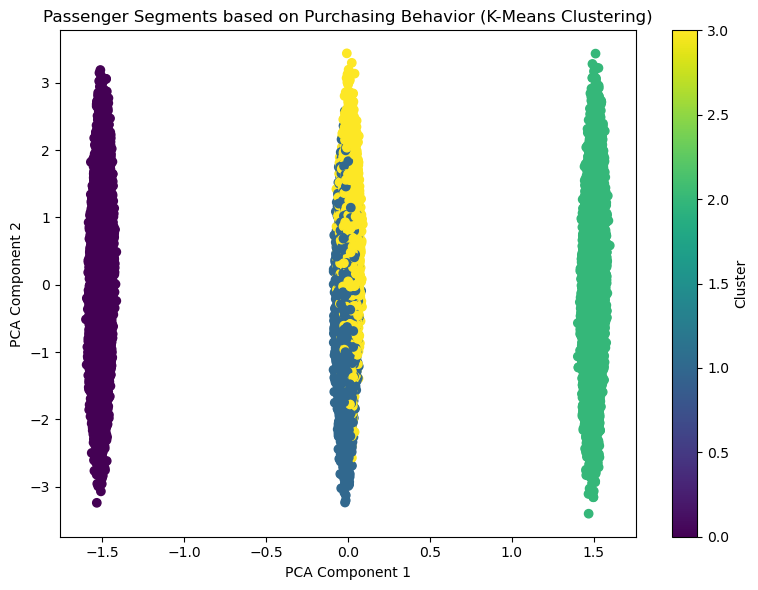

,Price,scheduled_departure_hour,scheduled_departure_dayofweek,Cluster
0,806,0,6,3
1,750,1,6,3
2,214,2,6,0
3,269,3,6,1
4,547,4,6,0


In [34]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
# Filling any missing values in the data
clustering_data.fillna(0, inplace=True)

# Standardizing the features
scaler = StandardScaler()
clustering_data_scaled = scaler.fit_transform(clustering_data)

# Applying KMeans clustering
kmeans = KMeans(n_clusters=4, random_state=42)
clusters = kmeans.fit_predict(clustering_data_scaled)

# Adding the cluster labels to the original dataset
Aero_data['Cluster'] = clusters

# Performing PCA for visualization (reducing the dimensions to 2D)
pca = PCA(n_components=2)
pca_data = pca.fit_transform(clustering_data_scaled)

# Creating a scatter plot for the PCA results colored by clusters
plt.figure(figsize=(8, 6))
plt.scatter(pca_data[:, 0], pca_data[:, 1], c=clusters, cmap='viridis')
plt.title('Passenger Segments based on Purchasing Behavior (K-Means Clustering)')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.colorbar(label='Cluster')
plt.tight_layout()
plt.show()

# Displaying the first few rows of the data with cluster labels
Aero_data[['Price', 'scheduled_departure_hour', 'scheduled_departure_dayofweek', 'Cluster']].head()

'''

we have visualized the passenger segments based on purchasing behavior using K-Means clustering. 
Clustering into 4 segments: 

The passengers were grouped into 4 distinct clusters.
PCA visualization: The scatter plot shows the clusters in 2D space after applying PCA to reduce the feature dimensions. 
Each color represents a different cluster.
The first few rows of the dataset, now with their respective cluster labels, are also displayed.
Each passenger has been assigned a cluster based on their purchasing behavior.


# What features most strongly influence flight prices? Are these features consistent across different airlines?

To determine which features most strongly influence flight prices, we use techniques such as feature importance
from regression models or correlation analysis. Afterward, 
we can analyze whether these features have a consistent influence across different airlines.

In [35]:
# First, let's perform a correlation analysis to see which features are most strongly correlated with flight prices.
correlation_matrix = Aero_data[['Price', 
                                    'scheduled_departure_hour', 
                                    'scheduled_departure_dayofweek', 
                                    'scheduled_departure_month', 
                                    'Holiday_List', 
                                    'Monthly_Air_Traffic', 
                                    'Average_household_income']].corr()

# Sorting the correlation of features with flight price to determine the strongest influences
price_correlation = correlation_matrix['Price'].sort_values(ascending=False)

# Display the correlation with flight price
price_correlation


Price                            1.000000
Average_household_income         0.008075
Monthly_Air_Traffic              0.007493
Holiday_List                     0.000806
scheduled_departure_hour        -0.000753
scheduled_departure_month       -0.003070
scheduled_departure_dayofweek   -0.003434
Name: Price, dtype: float64

'''
The correlation analysis indicates that none of the selected features have a very strong correlation with flight prices. However, some weak correlations are observed:

Average Household Income:  Slight positive correlation, suggesting that higher-income areas might have slightly higher ticket prices.

Monthly Air Traffic:  Minimal positive correlation with price, indicating a very weak relationship between overall traffic and prices.

'''

#  on which route Airline  is extremely used?

In [36]:
# Route Analysis: Finding the most frequently used route (based on origin and destination stations)
Aero_data['route'] = Aero_data['origin_station_code'] + " to " + Aero_data['destination_station_code']
most_frequent_route = Aero_data['route'].value_counts().idxmax()
route_count = Aero_data['route'].value_counts().max()

most_frequent_route,  route_count,

('LAX to LAS', 2135)

# b.. Performing Airline vs Price Analysis..
    ie find price distribution & 5-point summary of each Airline..

In [37]:
# Airline vs Price Analysis: Price distribution and 5-point summary for each airline
price_summary_per_airline = Aero_data.groupby('Airline_name')['Price'].describe()

In [38]:
price_summary_per_airline

,count,mean,std,min,25%,50%,75%,max
Airline_name,,,,,,,,
American Airlines,12583.000000,522.023524,275.298222,50.000000,283.000000,516.000000,760.000000,999.000000
Delta,12372.000000,523.352894,274.418995,50.000000,283.000000,522.000000,760.000000,999.000000
Southwest,12647.000000,521.684826,273.537465,50.000000,285.000000,521.000000,758.000000,999.000000
United,12398.000000,526.116632,274.301044,50.000000,288.250000,528.000000,762.000000,999.000000


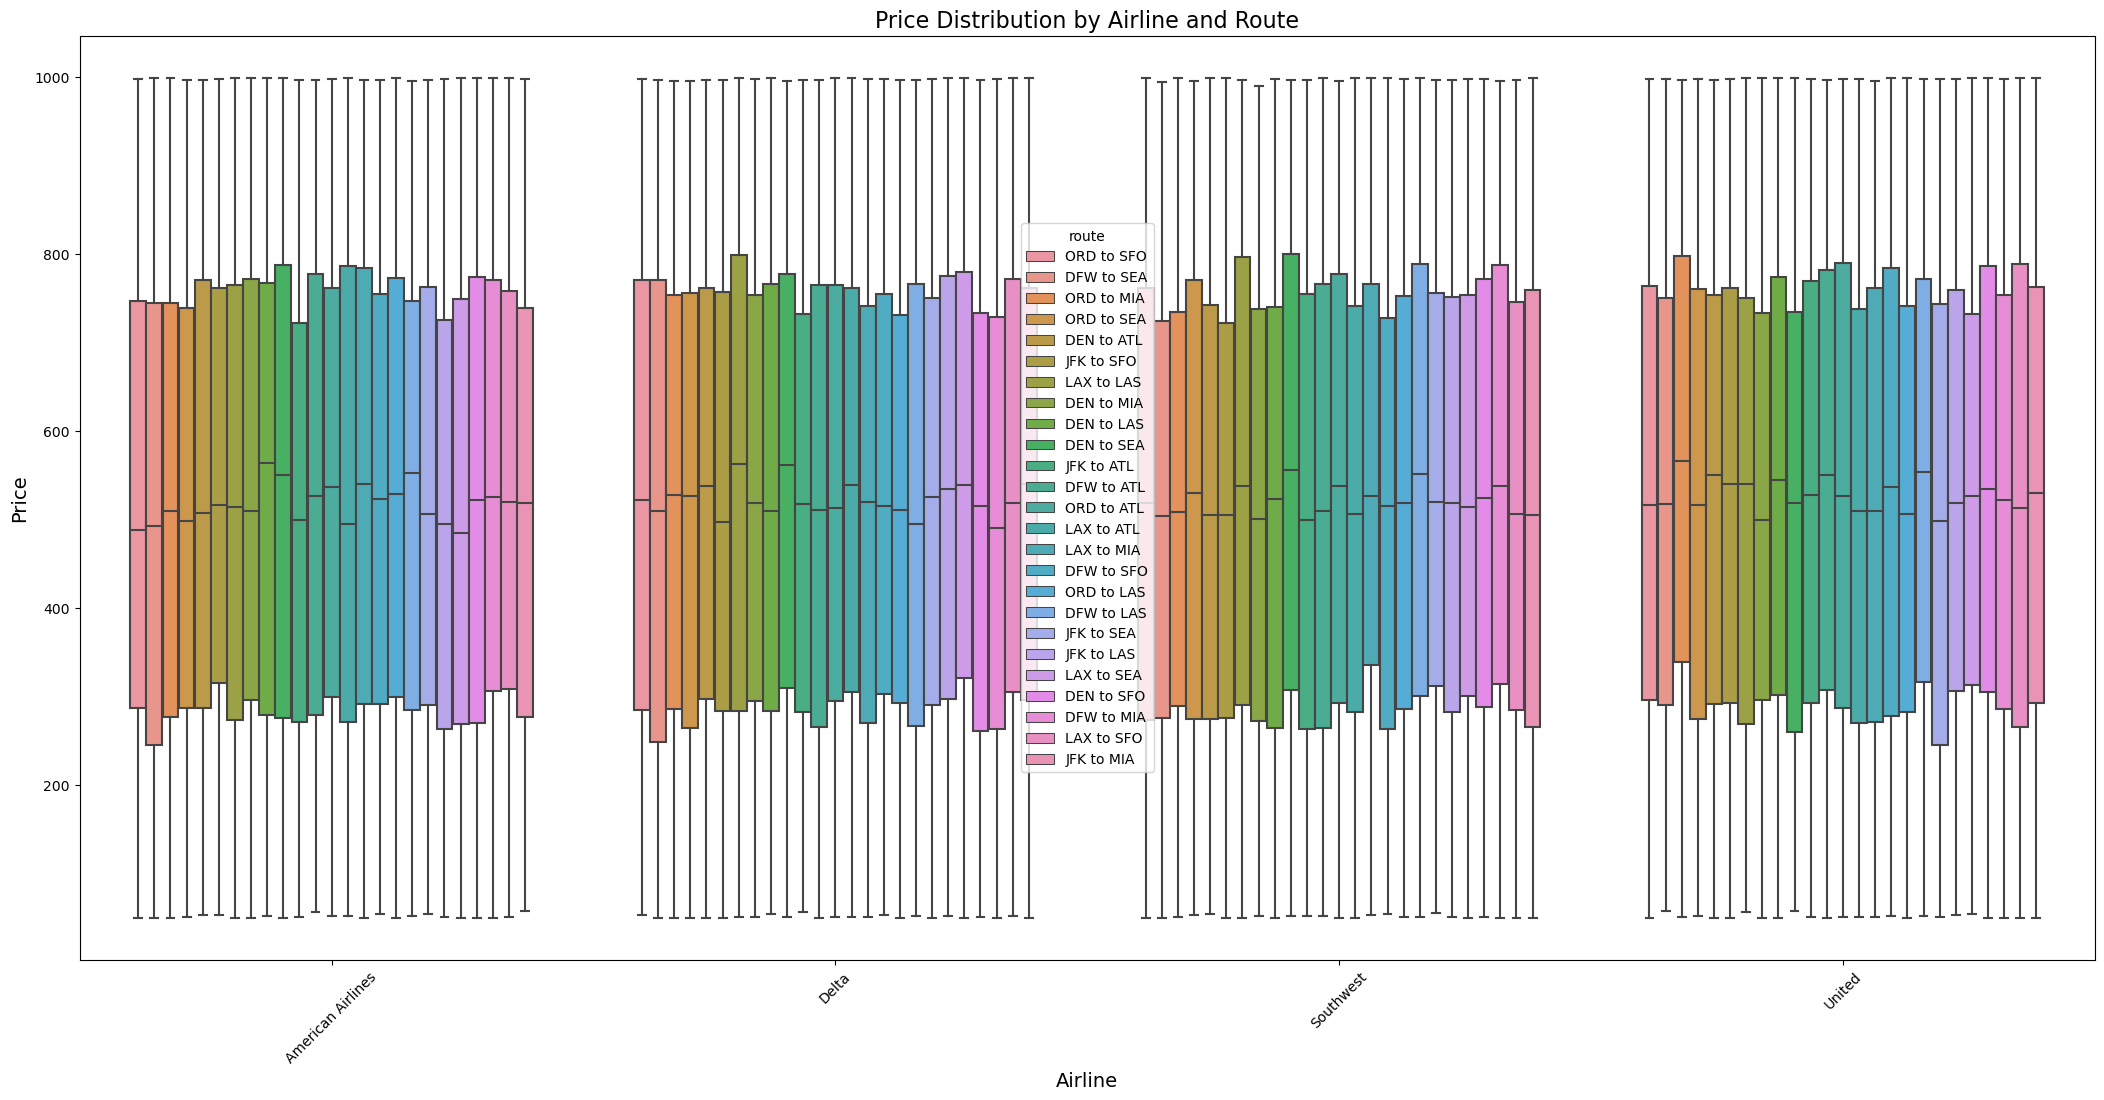

In [39]:
# We will use a boxplot to visualize the price distribution by airline and route
plt.figure(figsize=(26, 12))
sns.boxplot(x='Airline_name', y='Price', hue='route', data=Aero_data)

# Adding title and labels for clarity
plt.title('Price Distribution by Airline and Route', fontsize=16)
plt.xlabel('Airline', fontsize=14)
plt.ylabel('Price', fontsize=14)
plt.xticks(rotation=45)

# Displaying the plot
plt.show()

In [40]:
# Calculate price variance for each route and airline combination
route_airline_variance = Aero_data.groupby(['route', 'Airline_name'])['Price'].var().reset_index()

# Identify the routes with the highest and lowest price variance
highest_variance = route_airline_variance.loc[route_airline_variance['Price'].idxmax()]
lowest_variance = route_airline_variance.loc[route_airline_variance['Price'].idxmin()]

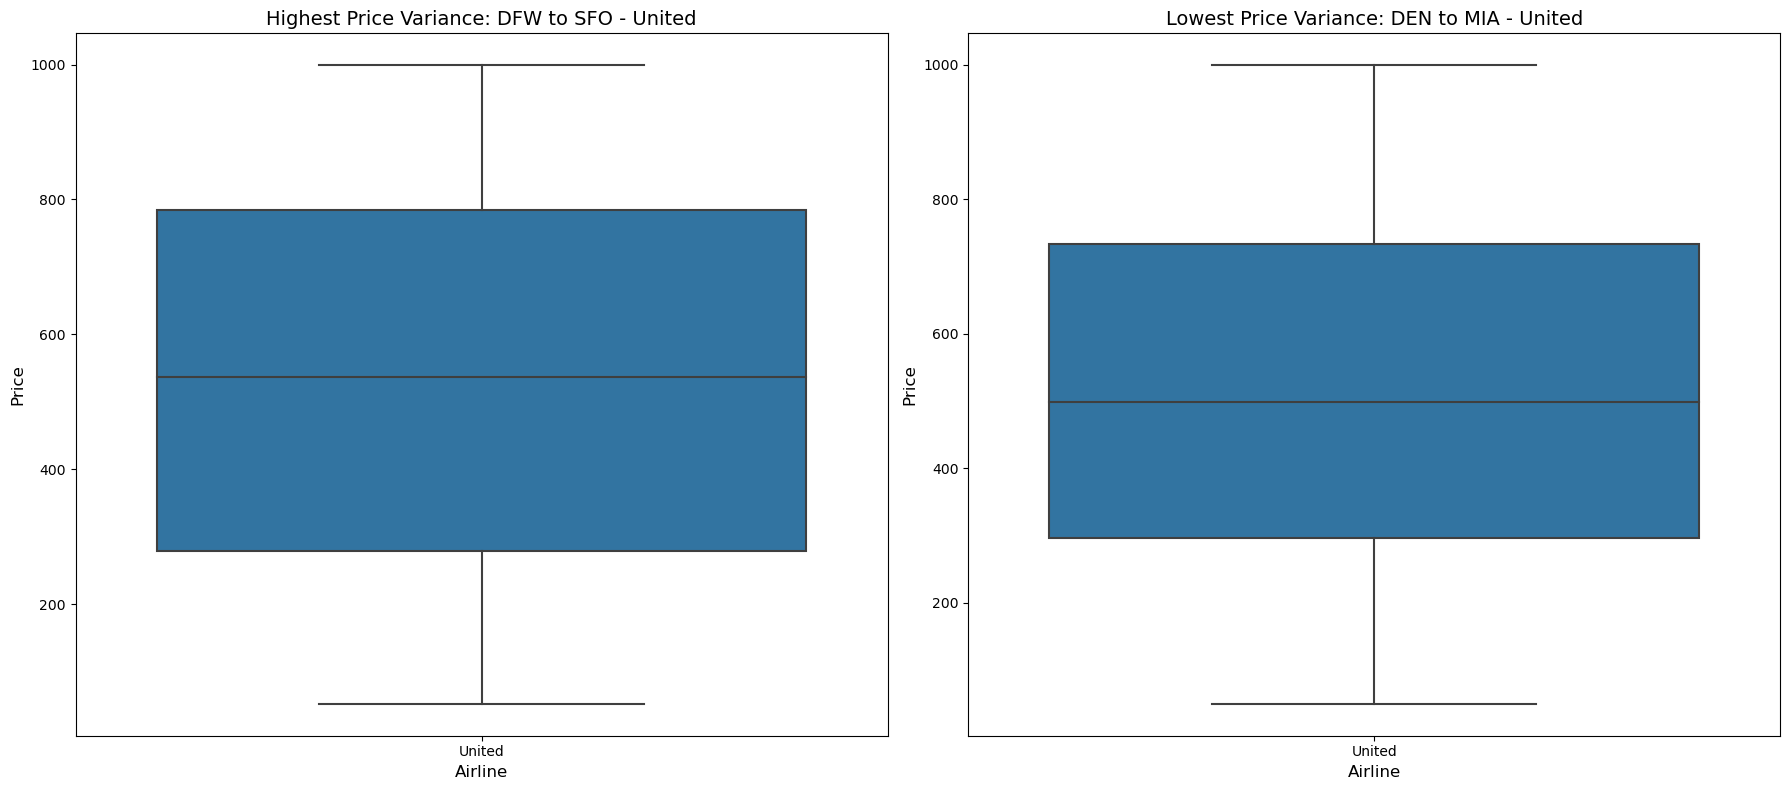

(route            DFW to SFO
 Airline_name         United
 Price          80876.678452
 Name: 39, dtype: object,
 route            DEN to MIA
 Airline_name         United
 Price          65790.390658
 Name: 11, dtype: object)

In [41]:
# Plotting the highest and lowest variance routes
fig, ax = plt.subplots(1, 2, figsize=(18, 8))

# Data for highest variance
highest_variance_data = Aero_data[(Aero_data['route'] == highest_variance['route']) & 
                                  (Aero_data['Airline_name'] == highest_variance['Airline_name'])]

sns.boxplot(x='Airline_name', y='Price', data=highest_variance_data, ax=ax[0])
ax[0].set_title(f"Highest Price Variance: {highest_variance['route']} - {highest_variance['Airline_name']}", fontsize=14)
ax[0].set_xlabel('Airline', fontsize=12)
ax[0].set_ylabel('Price', fontsize=12)

# Data for lowest variance
lowest_variance_data = Aero_data[(Aero_data['route'] == lowest_variance['route']) & 
                                 (Aero_data['Airline_name'] == lowest_variance['Airline_name'])]

sns.boxplot(x='Airline_name', y='Price', data=lowest_variance_data, ax=ax[1])
ax[1].set_title(f"Lowest Price Variance: {lowest_variance['route']} - {lowest_variance['Airline_name']}", fontsize=14)
ax[1].set_xlabel('Airline', fontsize=12)
ax[1].set_ylabel('Price', fontsize=12)

# Display the plots
plt.tight_layout()
plt.show()

# Display the highest and lowest variance routes and airlines
highest_variance, lowest_variance

In [42]:
'''

Conclusion--> From graph we can see that United Airline  have the highest Price 

'''


'\n\nConclusion--> From graph we can see that United Airline  have the highest Price \n\n'

# 9.. Applying one-hot Encoding on data..

In [43]:
Aero_data.head(2)

,origin_station_code,destination_station_code,scheduled_departure_date,cabin_code_desc,number_of_legs,seat_factor_band,loyalty_program_level,fleet_type_description,actual_flown_miles,haul_type,international_domestic_indicator,hub_spoke,flight_number,Atmosphere,Time_of_flight_booking,Remote_area_or_tourist_place,Airline_name,Date,Holiday_List,City,Monthly_Air_Traffic,Average_household_income,Price,scheduled_departure_day,scheduled_departure_month,scheduled_departure_year,scheduled_departure_dayofweek,scheduled_departure_hour,flight_booking_day,flight_booking_month,flight_booking_year,flight_booking_dayofweek,flight_booking_hour,Log_Price,Log_Monthly_Air_Traffic,Cluster,route
0,ORD,SFO,2023-01-01 00:00:00,Business,1,Low,None,B777,3690,Medium,International,Spoke,1612,Snowy,2023-01-01 00:00:00,Remote,American Airlines,2023-01-01 00:00:00,1,Los Angeles,30686,125277,806,1,1,2023,6,0,1,1,2023,6,0,6.693324,10.331594,3,ORD to SFO
1,DFW,SEA,2023-01-01 01:00:00,Business,1,High,Gold,A320,1937,Long,Domestic,Spoke,4694,Cloudy,2023-01-01 01:00:00,Remote,Delta,2023-01-01 01:00:00,1,Phoenix,47340,109465,750,1,1,2023,6,1,1,1,2023,6,1,6.621406,10.765132,3,DFW to SEA


In [44]:
'''

Categorical data refers to a data type that can be stored into groups/categories/labels 
Examples of categorical variables are  age group, educational level,blood type etc.. 


Numerical data refers to the data that is in the form of numbers, 
Examples of numerical data are height, weight, age etc.. 

Numerical data has two categories: discrete data and continuous data


Discrete data : It basically takes countable numbers like 1, 2, 3, 4, 5, and so on. 
                In case of infinity, these numbers will keep going on...
                age of a fly : 8 , 9 day etc..
                
Continuous data : which is continuous in nature 
                  amount of sugar , 11.2 kg  , temp of a city  , your bank balance ! 
                  
For example, number_of_legs and Holiday_List are discrete variables, 
whereas Average_household_income and actual_flown_miles  are continuous variables.

'''

'\n\nCategorical data refers to a data type that can be stored into groups/categories/labels \nExamples of categorical variables are  age group, educational level,blood type etc.. \n\n\nNumerical data refers to the data that is in the form of numbers, \nExamples of numerical data are height, weight, age etc.. \n\nNumerical data has two categories: discrete data and continuous data\n\n\nDiscrete data : It basically takes countable numbers like 1, 2, 3, 4, 5, and so on. \n                In case of infinity, these numbers will keep going on...\n                age of a fly : 8 , 9 day etc..\n                \nContinuous data : which is continuous in nature \n                  amount of sugar , 11.2 kg  , temp of a city  , your bank balance ! \n                  \nFor example, number_of_legs and Holiday_List are discrete variables, \nwhereas Average_household_income and actual_flown_miles  are continuous variables.\n\n'

In [45]:
cat_col = [col for col in Aero_data.columns if Aero_data[col].dtype=="object"]

In [46]:
num_col = [col for col in Aero_data.columns if Aero_data[col].dtype!="object"]

###### Handling Categorical Data


                       We are using 2 basic Encoding Techniques to convert Categorical data into some numerical format
                       Nominal data --> data are not in any order --> OneHotEncoder is used in this case
                       Ordinal data --> data are in order -->       LabelEncoder is used in this case

                       But in real-world , it is not necessary that u have to always One-hot or label , 
                       hence we will discuss more interesting approaches in upcoming sessions to do this !

In [47]:
cat_col

['origin_station_code',
 'destination_station_code',
 'cabin_code_desc',
 'seat_factor_band',
 'loyalty_program_level',
 'fleet_type_description',
 'haul_type',
 'international_domestic_indicator',
 'hub_spoke',
 'Atmosphere',
 'Remote_area_or_tourist_place',
 'Airline_name',
 'City',
 'route']

# Categorical Columns (for Dummy Variable Conversion):

######  use dummy encoding (also called one-hot encoding), which creates binary columns for each category in a feature

###### Why: Dummy encoding avoids treating categorical variables as ordinal (implying an order), which could introduce bias if the algorithm assumes a hierarchy in the categories.

In [49]:
# Convert all specified categorical columns into dummy variables in one go
categorical_columns = [
    'origin_station_code', 
    'destination_station_code', 
    'cabin_code_desc', 
    'seat_factor_band', 
    'loyalty_program_level', 
    'fleet_type_description',
    'haul_type', 
    'international_domestic_indicator',
    'hub_spoke',
    'Atmosphere',
    'Remote_area_or_tourist_place',
    'Airline_name',
    'City'
]

# Apply pd.get_dummies for the categorical columns with drop_first to avoid multicollinearity
Aero_data_df= pd.get_dummies(Aero_data, columns=categorical_columns, drop_first=True)

# Display the first few rows to observe the changes
print(Aero_data_df.head())

# Optional: Check the shape of the dataframe after the transformation
print(f"Dataset shape after dummy variable conversion: {Aero_data_df.shape}")


  scheduled_departure_date  number_of_legs  actual_flown_miles  flight_number  \
0      2023-01-01 00:00:00               1                3690           1612   
1      2023-01-01 01:00:00               1                1937           4694   
2      2023-01-01 02:00:00               1                 387           3396   
3      2023-01-01 03:00:00               2                2950           2900   
4      2023-01-01 04:00:00               1                1133           7438   

  Time_of_flight_booking                Date  Holiday_List  \
0    2023-01-01 00:00:00 2023-01-01 00:00:00             1   
1    2023-01-01 01:00:00 2023-01-01 01:00:00             1   
2    2023-01-01 02:00:00 2023-01-01 02:00:00             1   
3    2023-01-01 03:00:00 2023-01-01 03:00:00             0   
4    2023-01-01 04:00:00 2023-01-01 04:00:00             1   

   Monthly_Air_Traffic  Average_household_income  Price  \
0                30686                    125277    806   
1                47340

In [50]:
Aero_data_df.head(5)

,scheduled_departure_date,number_of_legs,actual_flown_miles,flight_number,Time_of_flight_booking,Date,Holiday_List,Monthly_Air_Traffic,Average_household_income,Price,scheduled_departure_day,scheduled_departure_month,scheduled_departure_year,scheduled_departure_dayofweek,scheduled_departure_hour,flight_booking_day,flight_booking_month,flight_booking_year,flight_booking_dayofweek,flight_booking_hour,Log_Price,Log_Monthly_Air_Traffic,Cluster,route,origin_station_code_DFW,origin_station_code_JFK,origin_station_code_LAX,origin_station_code_ORD,destination_station_code_LAS,destination_station_code_MIA,destination_station_code_SEA,destination_station_code_SFO,cabin_code_desc_Economy,cabin_code_desc_First,seat_factor_band_Low,seat_factor_band_Medium,loyalty_program_level_None,loyalty_program_level_Platinum,loyalty_program_level_Silver,fleet_type_description_A380,fleet_type_description_B737,fleet_type_description_B777,haul_type_Medium,haul_type_Short,international_domestic_indicator_International,hub_spoke_Spoke,Atmosphere_Cloudy,Atmosphere_Rainy,Atmosphere_Snowy,Remote_area_or_tourist_place_Tourist,Airline_name_Delta,Airline_name_Southwest,Airline_name_United,City_Houston,City_Los Angeles,City_New York,City_Phoenix
0,2023-01-01 00:00:00,1,3690,1612,2023-01-01 00:00:00,2023-01-01 00:00:00,1,30686,125277,806,1,1,2023,6,0,1,1,2023,6,0,6.693324,10.331594,3,ORD to SFO,0,0,0,1,0,0,0,1,0,0,1,0,1,0,0,0,0,1,1,0,1,1,0,0,1,0,0,0,0,0,1,0,0
1,2023-01-01 01:00:00,1,1937,4694,2023-01-01 01:00:00,2023-01-01 01:00:00,1,47340,109465,750,1,1,2023,6,1,1,1,2023,6,1,6.621406,10.765132,3,DFW to SEA,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,1,0,0,0,0,0,1
2,2023-01-01 02:00:00,1,387,3396,2023-01-01 02:00:00,2023-01-01 02:00:00,1,14587,142545,214,1,1,2023,6,2,1,1,2023,6,2,5.370638,9.587955,0,ORD to MIA,0,0,0,1,0,1,0,0,0,1,1,0,0,0,0,0,1,0,0,1,1,0,0,0,0,1,0,0,0,0,0,1,0
3,2023-01-01 03:00:00,2,2950,2900,2023-01-01 03:00:00,2023-01-01 03:00:00,0,39173,125946,269,1,1,2023,6,3,1,1,2023,6,3,5.598422,10.575769,1,ORD to SEA,0,0,0,1,0,0,1,0,0,0,0,0,0,0,1,0,0,1,1,0,0,0,0,1,0,1,0,1,0,1,0,0,0
4,2023-01-01 04:00:00,1,1133,7438,2023-01-01 04:00:00,2023-01-01 04:00:00,1,36514,66732,547,1,1,2023,6,4,1,1,2023,6,4,6.306275,10.505478,0,DEN to ATL,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,1,0,0,1,0,1,0,0,0,1,0,0,1,0,0,0,0,0


# Remove Un-necessary features:

In [52]:
Aero_data_df.head(1)

,scheduled_departure_date,number_of_legs,actual_flown_miles,flight_number,Time_of_flight_booking,Date,Holiday_List,Monthly_Air_Traffic,Average_household_income,Price,scheduled_departure_day,scheduled_departure_month,scheduled_departure_year,scheduled_departure_dayofweek,scheduled_departure_hour,flight_booking_day,flight_booking_month,flight_booking_year,flight_booking_dayofweek,flight_booking_hour,Log_Price,Log_Monthly_Air_Traffic,Cluster,route,origin_station_code_DFW,origin_station_code_JFK,origin_station_code_LAX,origin_station_code_ORD,destination_station_code_LAS,destination_station_code_MIA,destination_station_code_SEA,destination_station_code_SFO,cabin_code_desc_Economy,cabin_code_desc_First,seat_factor_band_Low,seat_factor_band_Medium,loyalty_program_level_None,loyalty_program_level_Platinum,loyalty_program_level_Silver,fleet_type_description_A380,fleet_type_description_B737,fleet_type_description_B777,haul_type_Medium,haul_type_Short,international_domestic_indicator_International,hub_spoke_Spoke,Atmosphere_Cloudy,Atmosphere_Rainy,Atmosphere_Snowy,Remote_area_or_tourist_place_Tourist,Airline_name_Delta,Airline_name_Southwest,Airline_name_United,City_Houston,City_Los Angeles,City_New York,City_Phoenix
0,2023-01-01,1,3690,1612,2023-01-01,2023-01-01,1,30686,125277,806,1,1,2023,6,0,1,1,2023,6,0,6.693324,10.331594,3,ORD to SFO,0,0,0,1,0,0,0,1,0,0,1,0,1,0,0,0,0,1,1,0,1,1,0,0,1,0,0,0,0,0,1,0,0


In [53]:
Aero_data_df.columns

Index(['scheduled_departure_date', 'number_of_legs', 'actual_flown_miles',
       'flight_number', 'Time_of_flight_booking', 'Date', 'Holiday_List',
       'Monthly_Air_Traffic', 'Average_household_income', 'Price',
       'scheduled_departure_day', 'scheduled_departure_month',
       'scheduled_departure_year', 'scheduled_departure_dayofweek',
       'scheduled_departure_hour', 'flight_booking_day',
       'flight_booking_month', 'flight_booking_year',
       'flight_booking_dayofweek', 'flight_booking_hour', 'Log_Price',
       'Log_Monthly_Air_Traffic', 'Cluster', 'route',
       'origin_station_code_DFW', 'origin_station_code_JFK',
       'origin_station_code_LAX', 'origin_station_code_ORD',
       'destination_station_code_LAS', 'destination_station_code_MIA',
       'destination_station_code_SEA', 'destination_station_code_SFO',
       'cabin_code_desc_Economy', 'cabin_code_desc_First',
       'seat_factor_band_Low', 'seat_factor_band_Medium',
       'loyalty_program_level_None',

In [ ]:
'''

lets drop scheduled_departure_date as well as we have already extracted "scheduled_departure_date_hour" , "scheduled_departure_date_month" , Journey_day"..
seat_factor_band contains almost 80% no_info , so we can drop this column ..
lets drop fleet_type_description asThe fleet type (airplane model) may not significantly impact the price unless certain airplane models are exclusively used for premium services.
Lets drop "destination_station_code" feature as well as we have already perform feature encoding on this Feature 
lets drop hub_spoke as well , This might be redundant Beacuseit closely correlates with origin_station_code and destination_station_code.

'''

In [54]:
# List of columns to drop
columns_to_drop = [
    'scheduled_departure_date', 
    'Time_of_flight_booking', 
    'Date', 
    'Log_Price', 
    'Log_Monthly_Air_Traffic',  
    'Cluster'
]

# Drop the specified columns
Aero_data_df = Aero_data_df.drop(columns=columns_to_drop)

# Check the shape of the dataframe after dropping the columns
print(f"Dataset shape after dropping columns: {Aero_data_df.shape}")


Dataset shape after dropping columns: (50000, 51)


In [57]:
# Drop the 'route' column from the dataset
Aero_data_df= Aero_data_df.drop(columns=['route'])

# Check the shape of the dataframe after dropping the 'route' column
print(f"Dataset shape after dropping 'route' column: {Aero_data_df.shape}")


Dataset shape after dropping 'route' column: (50000, 50)


In [58]:
Aero_data_df.head(1)

,number_of_legs,actual_flown_miles,flight_number,Holiday_List,Monthly_Air_Traffic,Average_household_income,Price,scheduled_departure_day,scheduled_departure_month,scheduled_departure_year,scheduled_departure_dayofweek,scheduled_departure_hour,flight_booking_day,flight_booking_month,flight_booking_year,flight_booking_dayofweek,flight_booking_hour,origin_station_code_DFW,origin_station_code_JFK,origin_station_code_LAX,origin_station_code_ORD,destination_station_code_LAS,destination_station_code_MIA,destination_station_code_SEA,destination_station_code_SFO,cabin_code_desc_Economy,cabin_code_desc_First,seat_factor_band_Low,seat_factor_band_Medium,loyalty_program_level_None,loyalty_program_level_Platinum,loyalty_program_level_Silver,fleet_type_description_A380,fleet_type_description_B737,fleet_type_description_B777,haul_type_Medium,haul_type_Short,international_domestic_indicator_International,hub_spoke_Spoke,Atmosphere_Cloudy,Atmosphere_Rainy,Atmosphere_Snowy,Remote_area_or_tourist_place_Tourist,Airline_name_Delta,Airline_name_Southwest,Airline_name_United,City_Houston,City_Los Angeles,City_New York,City_Phoenix
0,1,3690,1612,1,30686,125277,806,1,1,2023,6,0,1,1,2023,6,0,0,0,0,1,0,0,0,1,0,0,1,0,1,0,0,0,0,1,1,0,1,1,0,0,1,0,0,0,0,0,1,0,0


In [100]:
# Import the necessary library for scaling
from sklearn.preprocessing import StandardScaler

# Columns to be scaled as mentioned by the user
columns_to_scale = [
    'number_of_legs', 'actual_flown_miles', 'flight_number', 'Holiday_List', 
    'Monthly_Air_Traffic', 'Average_household_income', 'scheduled_departure_day', 
    'scheduled_departure_month', 'scheduled_departure_year', 'scheduled_departure_dayofweek', 
    'scheduled_departure_hour', 'flight_booking_day', 'flight_booking_month', 
    'flight_booking_year', 'flight_booking_dayofweek', 'flight_booking_hour',
    'origin_station_code_DFW', 'origin_station_code_JFK', 'origin_station_code_LAX', 
    'origin_station_code_ORD', 'destination_station_code_LAS', 'destination_station_code_MIA', 
    'destination_station_code_SEA', 'destination_station_code_SFO', 'cabin_code_desc_Economy', 
    'cabin_code_desc_First', 'seat_factor_band_Low', 'seat_factor_band_Medium', 
    'loyalty_program_level_None', 'loyalty_program_level_Platinum', 'loyalty_program_level_Silver', 
    'fleet_type_description_A380', 'fleet_type_description_B737', 'fleet_type_description_B777', 
    'haul_type_Medium', 'haul_type_Short', 'international_domestic_indicator_International', 
    'hub_spoke_Spoke', 'Atmosphere_Cloudy', 'Atmosphere_Rainy', 'Atmosphere_Snowy', 
    'Remote_area_or_tourist_place_Tourist', 'Airline_name_Delta', 'Airline_name_Southwest', 
    'Airline_name_United', 'City_Houston', 'City_Los Angeles', 'City_New York', 'City_Phoenix'
]

# Initialize the StandardScaler
scaler = StandardScaler()

# Fit the scaler to the data and transform the selected columns
Aero_data_df[columns_to_scale] = scaler.fit_transform(Aero_data_df[columns_to_scale])

# Display the first few rows after scaling to verify the transformation
Aero_data_df.head()


,number_of_legs,actual_flown_miles,flight_number,Holiday_List,Monthly_Air_Traffic,Average_household_income,Price,scheduled_departure_day,scheduled_departure_month,scheduled_departure_year,scheduled_departure_dayofweek,scheduled_departure_hour,flight_booking_day,flight_booking_month,flight_booking_year,flight_booking_dayofweek,flight_booking_hour,origin_station_code_DFW,origin_station_code_JFK,origin_station_code_LAX,origin_station_code_ORD,destination_station_code_LAS,destination_station_code_MIA,destination_station_code_SEA,destination_station_code_SFO,cabin_code_desc_Economy,cabin_code_desc_First,seat_factor_band_Low,seat_factor_band_Medium,loyalty_program_level_None,loyalty_program_level_Platinum,loyalty_program_level_Silver,fleet_type_description_A380,fleet_type_description_B737,fleet_type_description_B777,haul_type_Medium,haul_type_Short,international_domestic_indicator_International,hub_spoke_Spoke,Atmosphere_Cloudy,Atmosphere_Rainy,Atmosphere_Snowy,Remote_area_or_tourist_place_Tourist,Airline_name_Delta,Airline_name_Southwest,Airline_name_United,City_Houston,City_Los Angeles,City_New York,City_Phoenix
0,-0.995968,0.815064,-1.208163,0.999160,0.364870,0.954914,806,-1.666906,-1.563874,-1.435174,1.500210,-1.661081,-1.666906,-1.563874,-1.435174,1.500210,-1.661081,-0.502998,-0.501312,-0.499562,1.993027,-0.505712,-0.497530,-0.499000,2.004762,-0.704923,-0.701429,1.419043,-0.704192,1.728824,-0.574733,-0.578428,-0.578336,-0.571838,1.731497,1.418467,-0.709473,1.002042,1.002523,-0.581292,-0.572885,1.721036,-1.004812,-0.573409,-0.581877,-0.574209,-0.497092,2.014871,-0.502249,-0.501437
1,-0.995968,-0.428111,-0.128106,0.999160,1.544794,0.456016,750,-1.666906,-1.563874,-1.435174,1.500210,-1.516623,-1.666906,-1.563874,-1.435174,1.500210,-1.516623,1.988079,-0.501312,-0.499562,-0.501749,-0.505712,-0.497530,2.004009,-0.498812,-0.704923,-0.701429,-0.704700,-0.704192,-0.578428,-0.574733,-0.578428,-0.578336,-0.571838,-0.577535,-0.704987,-0.709473,-0.997962,1.002523,1.720307,-0.572885,-0.581045,-1.004812,1.743956,-0.581877,-0.574209,-0.497092,-0.496310,-0.502249,1.994268
2,-0.995968,-1.527325,-0.582978,0.999160,-0.775733,1.499752,214,-1.666906,-1.563874,-1.435174,1.500210,-1.372165,-1.666906,-1.563874,-1.435174,1.500210,-1.372165,-0.502998,-0.501312,-0.499562,1.993027,-0.505712,2.009929,-0.499000,-0.498812,-0.704923,1.425661,1.419043,-0.704192,-0.578428,-0.574733,-0.578428,-0.578336,1.748746,-0.577535,-0.704987,1.409496,1.002042,-0.997483,-0.581292,-0.572885,-0.581045,0.995211,-0.573409,-0.581877,-0.574209,-0.497092,-0.496310,1.991044,-0.501437
3,1.004048,0.290278,-0.756796,-1.000840,0.966168,0.976023,269,-1.666906,-1.563874,-1.435174,1.500210,-1.227707,-1.666906,-1.563874,-1.435174,1.500210,-1.227707,-0.502998,-0.501312,-0.499562,1.993027,-0.505712,-0.497530,2.004009,-0.498812,-0.704923,-0.701429,-0.704700,-0.704192,-0.578428,-0.574733,1.728824,-0.578336,-0.571838,1.731497,1.418467,-0.709473,-0.997962,-0.997483,-0.581292,1.745550,-0.581045,0.995211,-0.573409,1.718577,-0.574209,2.011700,-0.496310,-0.502249,-0.501437
4,-0.995968,-0.998284,0.833502,0.999160,0.777780,-0.892291,547,-1.666906,-1.563874,-1.435174,1.500210,-1.083249,-1.666906,-1.563874,-1.435174,1.500210,-1.083249,-0.502998,-0.501312,-0.499562,-0.501749,-0.505712,-0.497530,-0.499000,-0.498812,-0.704923,1.425661,-0.704700,1.420067,-0.578428,-0.574733,-0.578428,1.729100,-0.571838,-0.577535,1.418467,-0.709473,1.002042,-0.997483,-0.581292,-0.572885,1.721036,-1.004812,-0.573409,1.718577,-0.574209,-0.497092,-0.496310,-0.502249,-0.501437


# Building ML model:

#### split dataset into train & test

In [89]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score


In [103]:
from sklearn.model_selection import train_test_split

# Define the target variable (Price) and feature set (everything else)
X = Aero_data_df.drop('Price', axis=1)  # Features (independent variables)
y = Aero_data_df['Price']  # Target (dependent variable)

# Split the data into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Optional: Print the shapes of the resulting datasets
print(f"Training set size: {X_train.shape}, Testing set size: {X_test.shape}")


Training set size: (40000, 49), Testing set size: (10000, 49)


In [104]:
# Initialize the RandomForest model
model = RandomForestRegressor(random_state=42)

# Train the model on the training set
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate the model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse}")
print(f"R^2 Score: {r2}")

Mean Squared Error: 77236.53582174
R^2 Score: -0.018776880147325814


In [106]:
# Make predictions on the training set to evaluate performance
y_train_pred = model.predict(X_train)

# Evaluate the model performance on the training set
mse_train = mean_squared_error(y_train, y_train_pred)
r2_train = r2_score(y_train, y_train_pred)

print(f"Training Set Mean Squared Error: {mse_train}")
print(f"Training Set R^2 Score: {r2_train}")

Training Set Mean Squared Error: 10651.754757575
Training Set R^2 Score: 0.8582684587528959
